# Zero-Error Algorithm Comparison

This notebook runs the exact dynamic-programming algorithm and the greedy gain-based approximation on the complete 1D and 2D zero-error benchmarks.

It reports the numerical summaries used in the manuscript, includes an instance-difficulty check based on the exact minimum sensor budget $N_{min}^{opt}$, and displays the selected publication figures inline, including the $N_{min}^{opt}$ instance-difficulty figure. Existing benchmark inputs are reused by default; set `GENERATE_MISSING_INPUTS = True` only if the generated inputs are absent and must be recreated from the fixed benchmark definitions.


In [25]:
from pathlib import Path
from collections import defaultdict
import csv
import math
import sys

from IPython.display import Image, Markdown, display

# Resolve paths whether the notebook starts from the repository root or this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-sensor-zero-error"
    if (working_directory / "min-sensor-zero-error").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
SCRIPT_DIRECTORY = PROJECT_DIRECTORY / "scripts"
for directory in (SOURCE_DIRECTORY, SCRIPT_DIRECTORY):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

# Reload local modules when the notebook is restarted after code changes.
local_modules = (
    "optimal", "greedy", "phase_data", "field_models", "eval",
    "paper_analysis", "generate_inputs", "generate_benchmarks",
    "evaluate_benchmarks",
)
for module_name in local_modules:
    sys.modules.pop(module_name, None)

from evaluate_benchmarks import run_benchmark_evaluation
from paper_analysis import family_excess_table, guarantee_table, heatmap_table

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)
print("Script directory:", SCRIPT_DIRECTORY)


Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/src
Script directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/scripts


## Run Settings

`REPEATS` affects runtime averaging only. `BOOTSTRAP_ITERATIONS` controls confidence intervals. `GENERATE_MISSING_INPUTS = False` keeps the notebook on the saved benchmark inputs and prevents accidental data regeneration.


In [26]:
# Number of deterministic runs used to average each runtime measurement.
REPEATS = 1

# Number of stratified bootstrap samples used for confidence intervals.
BOOTSTRAP_ITERATIONS = 2_000

# Keep saved benchmark inputs fixed by default.
GENERATE_MISSING_INPUTS = False

print("Run mode: all 11,520 saved benchmark cases")
print("Runtime repetitions:", REPEATS)
print("Bootstrap iterations:", BOOTSTRAP_ITERATIONS)
print("Generate missing inputs:", GENERATE_MISSING_INPUTS)


Run mode: all 11,520 saved benchmark cases
Runtime repetitions: 1
Bootstrap iterations: 2000
Generate missing inputs: False


## Run Complete Evaluation

This cell evaluates both dimensions and creates the statistical analysis and figures. With the default settings, it requires the existing `benchmark_1d` and `benchmark_2d` inputs and does not regenerate data.


In [27]:
# Evaluate both dimensions and create the statistical analysis and figures.
analysis = run_benchmark_evaluation(
    repeats=REPEATS,
    bootstrap_iterations=BOOTSTRAP_ITERATIONS,
    generate_missing=GENERATE_MISSING_INPUTS,
)

# Stop if the analysis does not contain exactly the expected analysis figures.
ANALYSIS_FIGURES = ("families", "guarantee", "heatmaps")
if set(analysis["figures"]) != set(ANALYSIS_FIGURES):
    raise RuntimeError("The expected analysis figures were not created.")


Evaluating benchmark_1d ...
  5760 cases -> /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/results/algorithm_comparison/benchmark_1d_results_full/tables
Evaluating benchmark_2d ...
  5760 cases -> /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/results/algorithm_comparison/benchmark_2d_results_full/tables
Benchmark tables and figures -> /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/results/algorithm_comparison/results_summary_benchmark_1d_benchmark_2d_full


## Main Numerical Summary

The first row combines both dimensions. The following rows report 1D and 2D separately. The primary quality metric is the greedy-to-optimal sensor ratio, $N_{greedy}/N_{optimal}$.


In [28]:
# Format summary records as one Markdown table.
def summary_table(rows):
    header = (
        "| Group | Cases | Mean ratio | 95% CI | Exact-match rate | "
        "95th percentile | Maximum |\n"
        "|---|---:|---:|---:|---:|---:|---:|"
    )
    body = []
    for row in rows:
        body.append(
            f"| {row['group_value']} | {row['case_count']} | "
            f"{row['mean_greedy_ratio']:.3f} | "
            f"[{row['mean_greedy_ratio_ci95_low']:.3f}, "
            f"{row['mean_greedy_ratio_ci95_high']:.3f}] | "
            f"{100 * row['exact_match_rate']:.1f}% | "
            f"{row['p95_greedy_ratio']:.3f} | "
            f"{row['max_greedy_ratio']:.3f} |"
        )
    return header + "\n" + "\n".join(body)

summary_rows = [analysis["overall_summary"], *analysis["dimension_summaries"]]
display(Markdown(summary_table(summary_rows)))

| Group | Cases | Mean ratio | 95% CI | Exact-match rate | 95th percentile | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| combined | 11520 | 1.153 | [1.150, 1.156] | 30.4% | 1.488 | 2.280 |
| 1D | 5760 | 1.161 | [1.157, 1.166] | 28.7% | 1.500 | 2.280 |
| 2D | 5760 | 1.146 | [1.142, 1.150] | 32.0% | 1.479 | 2.164 |

## Figure Data Tables

These tables contain the numerical values used in the publication figures and the $N_{min}^{opt}$ instance-difficulty check. They are computed from the raw per-case results in `analysis["rows"]`, not from image files.


In [29]:
def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if formats.get(key) else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            value = row[key]
            values.append(formatter(value) if formatter else str(value))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])

heatmap_rows = heatmap_table(analysis["rows"])
display(Markdown("### Quality Heatmap Values"))
display(Markdown(markdown_table(
    heatmap_rows,
    (
        ("Dimension", "dimension"),
        ("K", "K"),
        ("M", "M"),
        ("Mean additional sensors used by Greedy (%)", "mean_additional_sensors_percent"),
    ),
    {"K": lambda value: f"{int(value)}", "M": lambda value: f"{int(value)}", "mean_additional_sensors_percent": lambda value: f"{float(value):.2f}"},
)))

family_rows = family_excess_table(
    analysis["rows"],
    bootstrap_iterations=BOOTSTRAP_ITERATIONS,
)
display(Markdown("### Field-Family Bar-Chart Values"))
display(Markdown(markdown_table(
    family_rows,
    (
        ("Dimension", "dimension"),
        ("Field family", "field_family"),
        ("K", "K"),
        ("Mean additional sensors used by Greedy (%)", "mean_additional_sensors_percent"),
        ("95% CI low", "ci95_low"),
        ("95% CI high", "ci95_high"),
    ),
    {
        "K": lambda value: f"{int(value)}",
        "mean_additional_sensors_percent": lambda value: f"{float(value):.2f}",
        "ci95_low": lambda value: f"{float(value):.2f}",
        "ci95_high": lambda value: f"{float(value):.2f}",
    },
)))

guarantee_rows = guarantee_table(analysis["rows"])
display(Markdown("### Approximation-Guarantee Figure Values"))
display(Markdown(markdown_table(
    guarantee_rows,
    (
        ("Dimension", "dimension"),
        ("Field family", "field_family"),
        ("K", "K"),
        ("Maximum worst-case allowance used (%)", "maximum_worst_case_allowance_used_percent"),
    ),
    {"K": lambda value: f"{int(value)}", "maximum_worst_case_allowance_used_percent": lambda value: f"{float(value):.2f}"},
)))


### Quality Heatmap Values

| Dimension | K | M | Mean additional sensors used by Greedy (%) |
|---|---:|---:|---:|
| 1D | 3 | 3 | 8.22 |
| 1D | 3 | 4 | 7.30 |
| 1D | 3 | 5 | 7.99 |
| 1D | 3 | 6 | 11.43 |
| 1D | 3 | 7 | 13.58 |
| 1D | 3 | 8 | 8.64 |
| 1D | 3 | 9 | 13.35 |
| 1D | 3 | 10 | 11.75 |
| 1D | 4 | 3 | 14.46 |
| 1D | 4 | 4 | 12.71 |
| 1D | 4 | 5 | 17.03 |
| 1D | 4 | 6 | 15.77 |
| 1D | 4 | 7 | 13.78 |
| 1D | 4 | 8 | 12.52 |
| 1D | 4 | 9 | 19.13 |
| 1D | 4 | 10 | 15.06 |
| 1D | 5 | 3 | 12.75 |
| 1D | 5 | 4 | 14.21 |
| 1D | 5 | 5 | 16.24 |
| 1D | 5 | 6 | 13.82 |
| 1D | 5 | 7 | 14.06 |
| 1D | 5 | 8 | 16.87 |
| 1D | 5 | 9 | 17.75 |
| 1D | 5 | 10 | 17.56 |
| 1D | 6 | 3 | 10.04 |
| 1D | 6 | 4 | 12.60 |
| 1D | 6 | 5 | 15.88 |
| 1D | 6 | 6 | 18.57 |
| 1D | 6 | 7 | 15.76 |
| 1D | 6 | 8 | 13.96 |
| 1D | 6 | 9 | 23.57 |
| 1D | 6 | 10 | 22.32 |
| 1D | 7 | 3 | 10.96 |
| 1D | 7 | 4 | 13.69 |
| 1D | 7 | 5 | 18.71 |
| 1D | 7 | 6 | 15.90 |
| 1D | 7 | 7 | 17.36 |
| 1D | 7 | 8 | 19.78 |
| 1D | 7 | 9 | 18.20 |
| 1D | 7 | 10 | 21.60 |
| 1D | 8 | 3 | 11.53 |
| 1D | 8 | 4 | 15.13 |
| 1D | 8 | 5 | 16.30 |
| 1D | 8 | 6 | 15.65 |
| 1D | 8 | 7 | 18.53 |
| 1D | 8 | 8 | 21.34 |
| 1D | 8 | 9 | 21.02 |
| 1D | 8 | 10 | 19.69 |
| 1D | 9 | 3 | 12.38 |
| 1D | 9 | 4 | 14.45 |
| 1D | 9 | 5 | 17.66 |
| 1D | 9 | 6 | 18.08 |
| 1D | 9 | 7 | 21.86 |
| 1D | 9 | 8 | 17.88 |
| 1D | 9 | 9 | 21.34 |
| 1D | 9 | 10 | 23.71 |
| 1D | 10 | 3 | 11.81 |
| 1D | 10 | 4 | 13.67 |
| 1D | 10 | 5 | 19.82 |
| 1D | 10 | 6 | 17.68 |
| 1D | 10 | 7 | 20.93 |
| 1D | 10 | 8 | 20.70 |
| 1D | 10 | 9 | 22.94 |
| 1D | 10 | 10 | 22.91 |
| 2D | 3 | 3 | 10.42 |
| 2D | 3 | 4 | 9.94 |
| 2D | 3 | 5 | 10.38 |
| 2D | 3 | 6 | 11.48 |
| 2D | 3 | 7 | 10.34 |
| 2D | 3 | 8 | 11.53 |
| 2D | 3 | 9 | 12.34 |
| 2D | 3 | 10 | 9.90 |
| 2D | 4 | 3 | 9.72 |
| 2D | 4 | 4 | 14.17 |
| 2D | 4 | 5 | 12.94 |
| 2D | 4 | 6 | 12.42 |
| 2D | 4 | 7 | 11.25 |
| 2D | 4 | 8 | 12.58 |
| 2D | 4 | 9 | 11.52 |
| 2D | 4 | 10 | 11.60 |
| 2D | 5 | 3 | 9.10 |
| 2D | 5 | 4 | 14.70 |
| 2D | 5 | 5 | 13.17 |
| 2D | 5 | 6 | 15.97 |
| 2D | 5 | 7 | 16.06 |
| 2D | 5 | 8 | 16.29 |
| 2D | 5 | 9 | 13.80 |
| 2D | 5 | 10 | 15.98 |
| 2D | 6 | 3 | 10.15 |
| 2D | 6 | 4 | 13.19 |
| 2D | 6 | 5 | 14.27 |
| 2D | 6 | 6 | 16.79 |
| 2D | 6 | 7 | 16.27 |
| 2D | 6 | 8 | 17.40 |
| 2D | 6 | 9 | 14.68 |
| 2D | 6 | 10 | 16.52 |
| 2D | 7 | 3 | 11.90 |
| 2D | 7 | 4 | 12.42 |
| 2D | 7 | 5 | 15.36 |
| 2D | 7 | 6 | 14.12 |
| 2D | 7 | 7 | 16.30 |
| 2D | 7 | 8 | 18.15 |
| 2D | 7 | 9 | 21.16 |
| 2D | 7 | 10 | 16.58 |
| 2D | 8 | 3 | 12.66 |
| 2D | 8 | 4 | 12.55 |
| 2D | 8 | 5 | 14.63 |
| 2D | 8 | 6 | 19.24 |
| 2D | 8 | 7 | 14.54 |
| 2D | 8 | 8 | 18.46 |
| 2D | 8 | 9 | 17.32 |
| 2D | 8 | 10 | 16.35 |
| 2D | 9 | 3 | 13.16 |
| 2D | 9 | 4 | 14.68 |
| 2D | 9 | 5 | 14.16 |
| 2D | 9 | 6 | 15.65 |
| 2D | 9 | 7 | 18.28 |
| 2D | 9 | 8 | 17.06 |
| 2D | 9 | 9 | 17.32 |
| 2D | 9 | 10 | 20.45 |
| 2D | 10 | 3 | 12.08 |
| 2D | 10 | 4 | 15.00 |
| 2D | 10 | 5 | 15.54 |
| 2D | 10 | 6 | 17.28 |
| 2D | 10 | 7 | 17.61 |
| 2D | 10 | 8 | 16.37 |
| 2D | 10 | 9 | 18.65 |
| 2D | 10 | 10 | 20.74 |

### Field-Family Bar-Chart Values

| Dimension | Field family | K | Mean additional sensors used by Greedy (%) | 95% CI low | 95% CI high |
|---|---|---:|---:|---:|---:|
| 1D | gaussian | 3 | 9.89 | 8.11 | 11.84 |
| 1D | gaussian | 4 | 14.84 | 12.47 | 17.17 |
| 1D | gaussian | 5 | 15.67 | 13.55 | 18.01 |
| 1D | gaussian | 6 | 15.69 | 13.69 | 17.71 |
| 1D | gaussian | 7 | 18.15 | 16.37 | 19.97 |
| 1D | gaussian | 8 | 18.22 | 16.30 | 20.06 |
| 1D | gaussian | 9 | 18.83 | 16.80 | 21.00 |
| 1D | gaussian | 10 | 18.66 | 16.82 | 20.67 |
| 1D | sinusoidal | 3 | 8.58 | 6.87 | 10.33 |
| 1D | sinusoidal | 4 | 14.22 | 12.01 | 16.45 |
| 1D | sinusoidal | 5 | 14.55 | 12.61 | 16.61 |
| 1D | sinusoidal | 6 | 16.50 | 14.61 | 18.55 |
| 1D | sinusoidal | 7 | 17.44 | 15.48 | 19.46 |
| 1D | sinusoidal | 8 | 19.07 | 17.37 | 20.81 |
| 1D | sinusoidal | 9 | 19.70 | 17.67 | 21.72 |
| 1D | sinusoidal | 10 | 22.48 | 20.60 | 24.49 |
| 1D | quadratic | 3 | 12.38 | 10.12 | 14.54 |
| 1D | quadratic | 4 | 16.11 | 13.93 | 18.43 |
| 1D | quadratic | 5 | 16.00 | 13.90 | 18.43 |
| 1D | quadratic | 6 | 17.58 | 15.19 | 19.82 |
| 1D | quadratic | 7 | 15.48 | 13.62 | 17.34 |
| 1D | quadratic | 8 | 14.91 | 13.12 | 16.84 |
| 1D | quadratic | 9 | 16.73 | 14.67 | 18.87 |
| 1D | quadratic | 10 | 15.28 | 13.20 | 17.26 |
| 2D | gaussian | 3 | 5.72 | 4.18 | 7.42 |
| 2D | gaussian | 4 | 6.48 | 5.09 | 8.01 |
| 2D | gaussian | 5 | 9.47 | 8.05 | 11.07 |
| 2D | gaussian | 6 | 10.21 | 8.74 | 11.74 |
| 2D | gaussian | 7 | 11.08 | 9.74 | 12.56 |
| 2D | gaussian | 8 | 10.10 | 8.88 | 11.40 |
| 2D | gaussian | 9 | 11.34 | 10.00 | 12.85 |
| 2D | gaussian | 10 | 11.36 | 10.10 | 12.73 |
| 2D | sinusoidal | 3 | 7.86 | 5.96 | 9.93 |
| 2D | sinusoidal | 4 | 9.13 | 7.30 | 11.05 |
| 2D | sinusoidal | 5 | 12.28 | 10.39 | 14.35 |
| 2D | sinusoidal | 6 | 12.73 | 11.07 | 14.45 |
| 2D | sinusoidal | 7 | 12.37 | 10.89 | 13.94 |
| 2D | sinusoidal | 8 | 15.02 | 13.30 | 16.80 |
| 2D | sinusoidal | 9 | 15.84 | 14.28 | 17.42 |
| 2D | sinusoidal | 10 | 15.81 | 14.25 | 17.54 |
| 2D | quadratic | 3 | 18.79 | 16.61 | 21.09 |
| 2D | quadratic | 4 | 20.46 | 18.15 | 22.80 |
| 2D | quadratic | 5 | 21.39 | 18.83 | 23.90 |
| 2D | quadratic | 6 | 21.78 | 19.02 | 24.51 |
| 2D | quadratic | 7 | 23.80 | 21.16 | 26.45 |
| 2D | quadratic | 8 | 22.04 | 19.47 | 24.63 |
| 2D | quadratic | 9 | 21.86 | 19.68 | 24.05 |
| 2D | quadratic | 10 | 22.80 | 20.27 | 25.33 |

### Approximation-Guarantee Figure Values

| Dimension | Field family | K | Maximum worst-case allowance used (%) |
|---|---|---:|---:|
| 1D | gaussian | 3 | 60.68 |
| 1D | gaussian | 4 | 50.23 |
| 1D | gaussian | 5 | 38.00 |
| 1D | gaussian | 6 | 31.89 |
| 1D | gaussian | 7 | 26.87 |
| 1D | gaussian | 8 | 24.38 |
| 1D | gaussian | 9 | 20.79 |
| 1D | gaussian | 10 | 24.42 |
| 1D | sinusoidal | 3 | 60.68 |
| 1D | sinusoidal | 4 | 41.86 |
| 1D | sinusoidal | 5 | 43.43 |
| 1D | sinusoidal | 6 | 29.01 |
| 1D | sinusoidal | 7 | 28.47 |
| 1D | sinusoidal | 8 | 21.18 |
| 1D | sinusoidal | 9 | 21.70 |
| 1D | sinusoidal | 10 | 21.89 |
| 1D | quadratic | 3 | 60.68 |
| 1D | quadratic | 4 | 51.82 |
| 1D | quadratic | 5 | 40.33 |
| 1D | quadratic | 6 | 47.27 |
| 1D | quadratic | 7 | 23.22 |
| 1D | quadratic | 8 | 23.03 |
| 1D | quadratic | 9 | 23.48 |
| 1D | quadratic | 10 | 19.50 |
| 2D | gaussian | 3 | 60.68 |
| 2D | gaussian | 4 | 40.79 |
| 2D | gaussian | 5 | 29.71 |
| 2D | gaussian | 6 | 22.40 |
| 2D | gaussian | 7 | 19.28 |
| 2D | gaussian | 8 | 15.29 |
| 2D | gaussian | 9 | 18.86 |
| 2D | gaussian | 10 | 18.19 |
| 2D | sinusoidal | 3 | 60.68 |
| 2D | sinusoidal | 4 | 55.81 |
| 2D | sinusoidal | 5 | 36.19 |
| 2D | sinusoidal | 6 | 20.51 |
| 2D | sinusoidal | 7 | 18.25 |
| 2D | sinusoidal | 8 | 18.01 |
| 2D | sinusoidal | 9 | 19.09 |
| 2D | sinusoidal | 10 | 17.51 |
| 2D | quadratic | 3 | 60.68 |
| 2D | quadratic | 4 | 46.51 |
| 2D | quadratic | 5 | 40.43 |
| 2D | quadratic | 6 | 38.69 |
| 2D | quadratic | 7 | 37.74 |
| 2D | quadratic | 8 | 28.47 |
| 2D | quadratic | 9 | 22.64 |
| 2D | quadratic | 10 | 30.57 |

## Instance $N_{min}^{opt}$ Summary

This section checks the difficulty of the regenerated zero-error benchmark instances. Here $N_{min}^{opt}$ is the exact minimum total number of sensors returned by the dynamic program for a case. The table reports the distribution of $N_{min}^{opt}$ by spatial dimension and number of candidate fields $K$; the corresponding mean-trend plot is included below as a selected publication figure.


In [30]:
def percentile(values, probability):
    ordered = sorted(float(value) for value in values)
    if not ordered:
        raise ValueError("Cannot calculate a percentile of an empty sample")
    position = probability * (len(ordered) - 1)
    lower = math.floor(position)
    upper = math.ceil(position)
    if lower == upper:
        return ordered[lower]
    weight = position - lower
    return ordered[lower] * (1 - weight) + ordered[upper] * weight


nmin_groups = defaultdict(list)
for row in analysis["rows"]:
    nmin_groups[(int(row["spatial_dimension"]), int(row["K"]))].append(float(row["N_optimal"]))

nmin_rows = []
for (dimension, K), values in sorted(nmin_groups.items()):
    nmin_rows.append({
        "dimension": f"{dimension}D",
        "K": K,
        "case_count": len(values),
        "mean_N_min_opt": sum(values) / len(values),
        "median_N_min_opt": percentile(values, 0.50),
        "p95_N_min_opt": percentile(values, 0.95),
        "maximum_N_min_opt": max(values),
    })

nmin_table_path = Path(analysis["output_directory"]) / "tables" / "nmin_by_dimension_k.csv"
with nmin_table_path.open("w", encoding="utf-8", newline="") as output_file:
    writer = csv.DictWriter(output_file, fieldnames=list(nmin_rows[0]), lineterminator="\n")
    writer.writeheader()
    writer.writerows(nmin_rows)

display(Markdown("### Exact Minimum Sensor Budget by Dimension and K"))
display(Markdown(markdown_table(
    nmin_rows,
    (
        ("Dimension", "dimension"),
        ("K", "K"),
        ("Cases", "case_count"),
        ("Mean $N_{min}^{opt}$", "mean_N_min_opt"),
        ("Median $N_{min}^{opt}$", "median_N_min_opt"),
        ("95th percentile", "p95_N_min_opt"),
        ("Maximum", "maximum_N_min_opt"),
    ),
    {
        "K": lambda value: f"{int(value)}",
        "case_count": lambda value: f"{int(value)}",
        "mean_N_min_opt": lambda value: f"{float(value):.2f}",
        "median_N_min_opt": lambda value: f"{float(value):.0f}",
        "p95_N_min_opt": lambda value: f"{float(value):.0f}",
        "maximum_N_min_opt": lambda value: f"{float(value):.0f}",
    },
)))

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.serif": ["Times New Roman"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
    "figure.titlesize": 12,
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

figure, axis = plt.subplots(figsize=(6.4, 4.0))
colors = {"1D": "#0072B2", "2D": "#009E73"}
line_styles = {"1D": "-", "2D": ":"}
markers = {"1D": "o", "2D": "s"}
for dimension_label in ("1D", "2D"):
    series = [row for row in nmin_rows if row["dimension"] == dimension_label]
    axis.plot(
        [int(row["K"]) for row in series],
        [float(row["mean_N_min_opt"]) for row in series],
        marker=markers[dimension_label],
        linestyle=line_styles[dimension_label],
        linewidth=1.8,
        color=colors[dimension_label],
        label=dimension_label,
    )
axis.set_xlabel(r"Number of candidate fields, $K$")
axis.set_ylabel(r"Mean exact minimum sensor budget, $N_{min}^{opt}$")
axis.grid(alpha=0.25)
axis.legend(frameon=False)
figure.tight_layout()

nmin_figure_directory = Path(analysis["output_directory"]) / "figures"
nmin_figure_directory.mkdir(parents=True, exist_ok=True)
figure.savefig(nmin_figure_directory / "benchmark_nmin_by_k.pdf", bbox_inches="tight")
figure.savefig(nmin_figure_directory / "benchmark_nmin_by_k.png", dpi=300, bbox_inches="tight")

nmin_png_path = nmin_figure_directory / "benchmark_nmin_by_k.png"

print("Saved N_min table:", nmin_table_path)
print("Saved N_min figure:", nmin_png_path)


### Exact Minimum Sensor Budget by Dimension and K

| Dimension | K | Cases | Mean $N_{min}^{opt}$ | Median $N_{min}^{opt}$ | 95th percentile | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 720 | 12.43 | 9 | 28 | 215 |
| 1D | 4 | 720 | 19.35 | 15 | 46 | 285 |
| 1D | 5 | 720 | 27.35 | 19 | 78 | 180 |
| 1D | 6 | 720 | 31.35 | 24 | 81 | 213 |
| 1D | 7 | 720 | 37.55 | 28 | 91 | 265 |
| 1D | 8 | 720 | 42.11 | 34 | 96 | 309 |
| 1D | 9 | 720 | 50.43 | 40 | 132 | 364 |
| 1D | 10 | 720 | 54.27 | 44 | 133 | 318 |
| 2D | 3 | 720 | 15.84 | 11 | 44 | 312 |
| 2D | 4 | 720 | 24.45 | 17 | 72 | 587 |
| 2D | 5 | 720 | 32.39 | 24 | 93 | 356 |
| 2D | 6 | 720 | 40.43 | 30 | 130 | 389 |
| 2D | 7 | 720 | 45.48 | 37 | 122 | 465 |
| 2D | 8 | 720 | 52.42 | 43 | 136 | 483 |
| 2D | 9 | 720 | 59.84 | 51 | 165 | 362 |
| 2D | 10 | 720 | 65.92 | 57 | 174 | 520 |

Saved N_min table: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/results/algorithm_comparison/results_summary_benchmark_1d_benchmark_2d_full/tables/nmin_by_dimension_k.csv
Saved N_min figure: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-sensor-zero-error/results/algorithm_comparison/results_summary_benchmark_1d_benchmark_2d_full/figures/benchmark_nmin_by_k.png


## Selected Publication Figures

1. **Sensor excess by field family:** compares Gaussian, sinusoidal, and quadratic fields across $K$.
2. **Approximation guarantee comparison:** shows how much of the theoretical sensor-excess allowance was used.
3. **Quality heatmaps:** shows mean Greedy sensor excess across $K$ and $M$.
4. **Exact minimum sensor budget:** reports the mean $N_{min}^{opt}$ trend for the regenerated 1D and 2D benchmark instances.

All figure text is formatted with Times New Roman, 12 pt. Categorical colors use a color-blind-safe blue, green, and orange palette. The $N_{min}^{opt}$ curves are distinguished by line style and marker shape.


### Sensor excess by field family

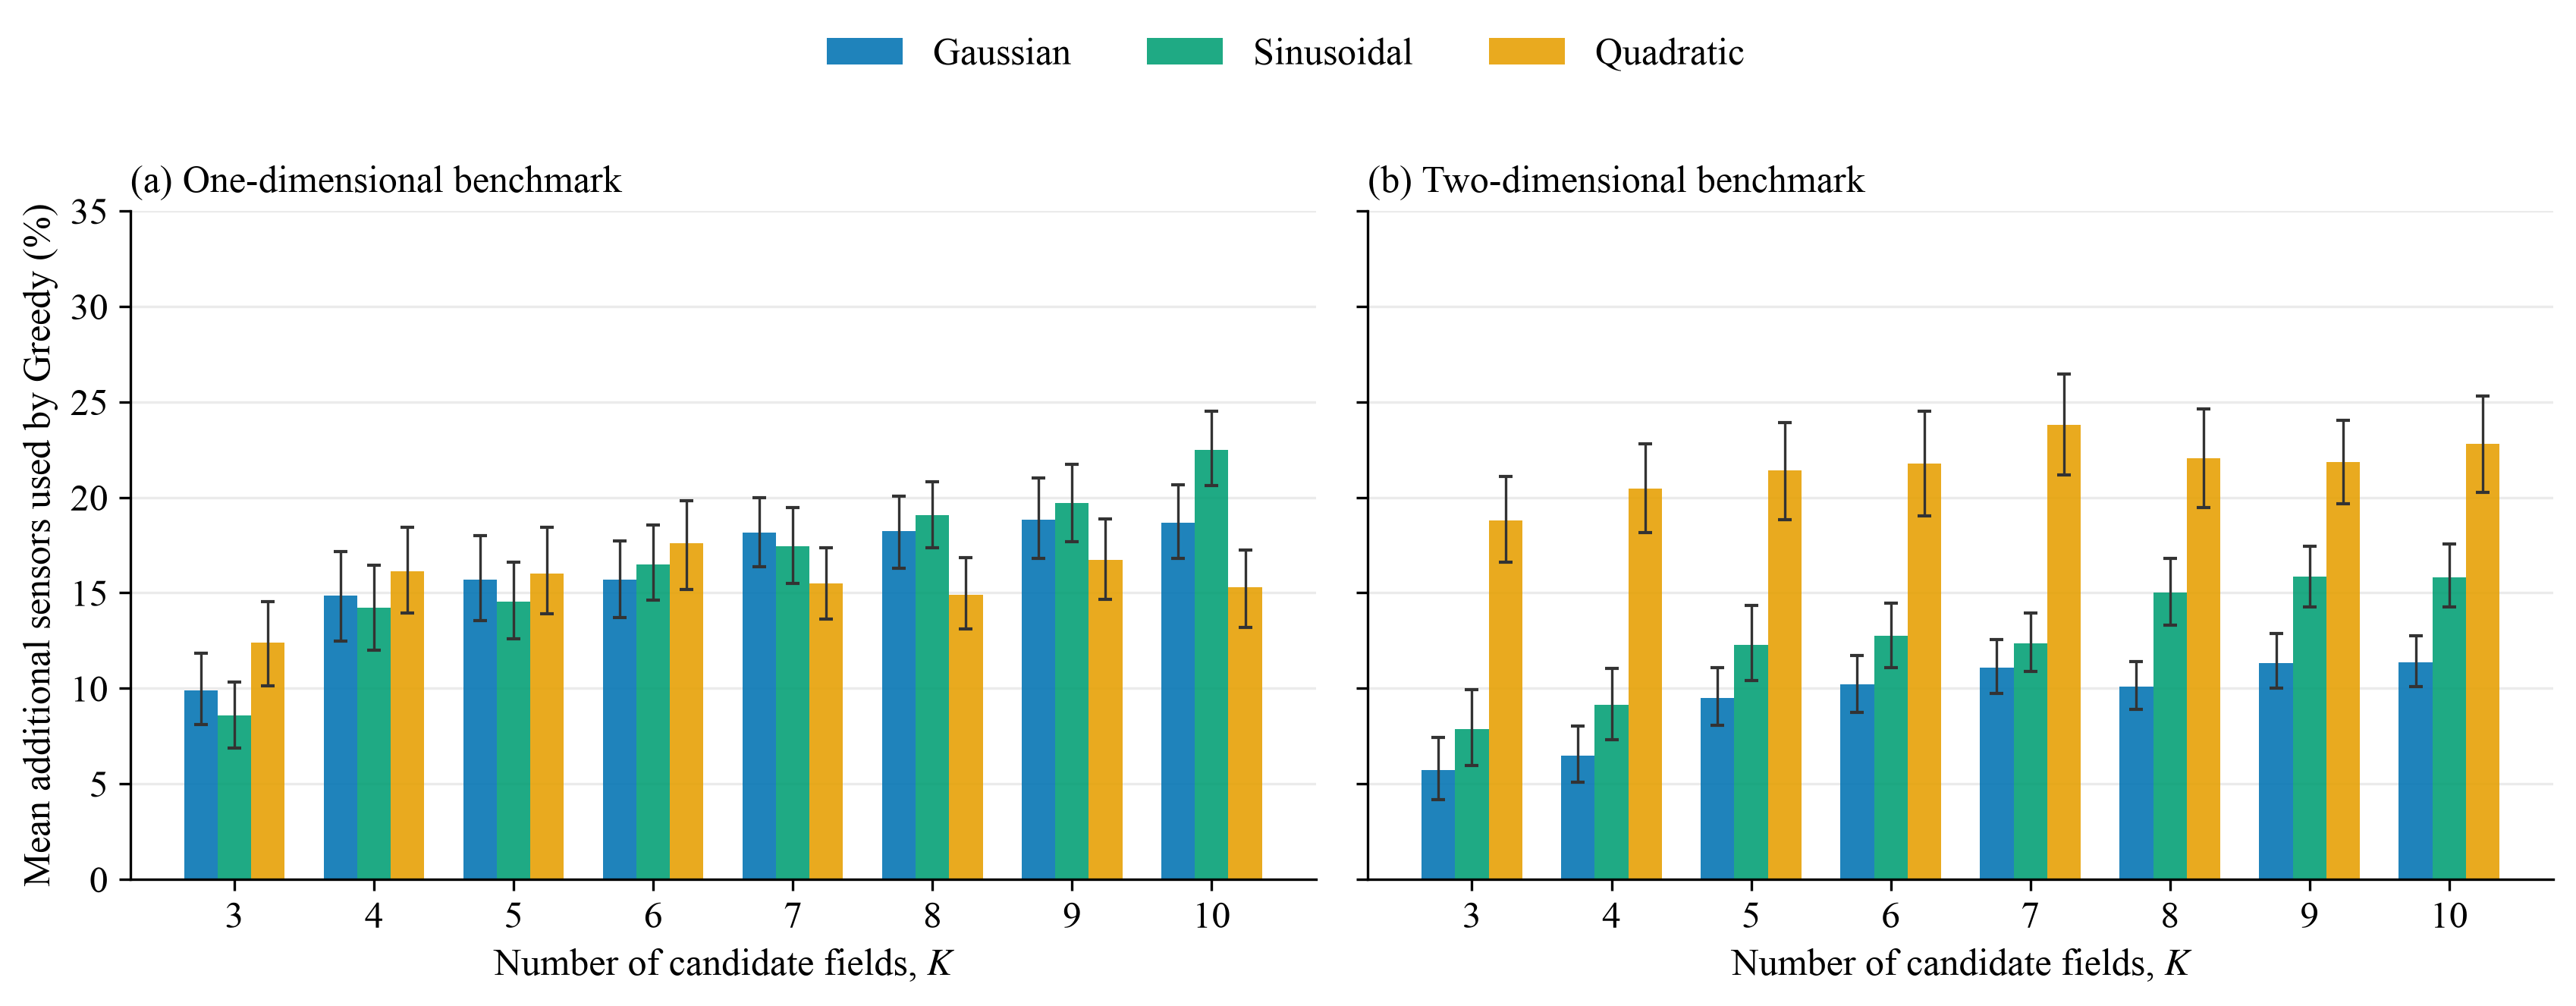

### Approximation guarantee comparison

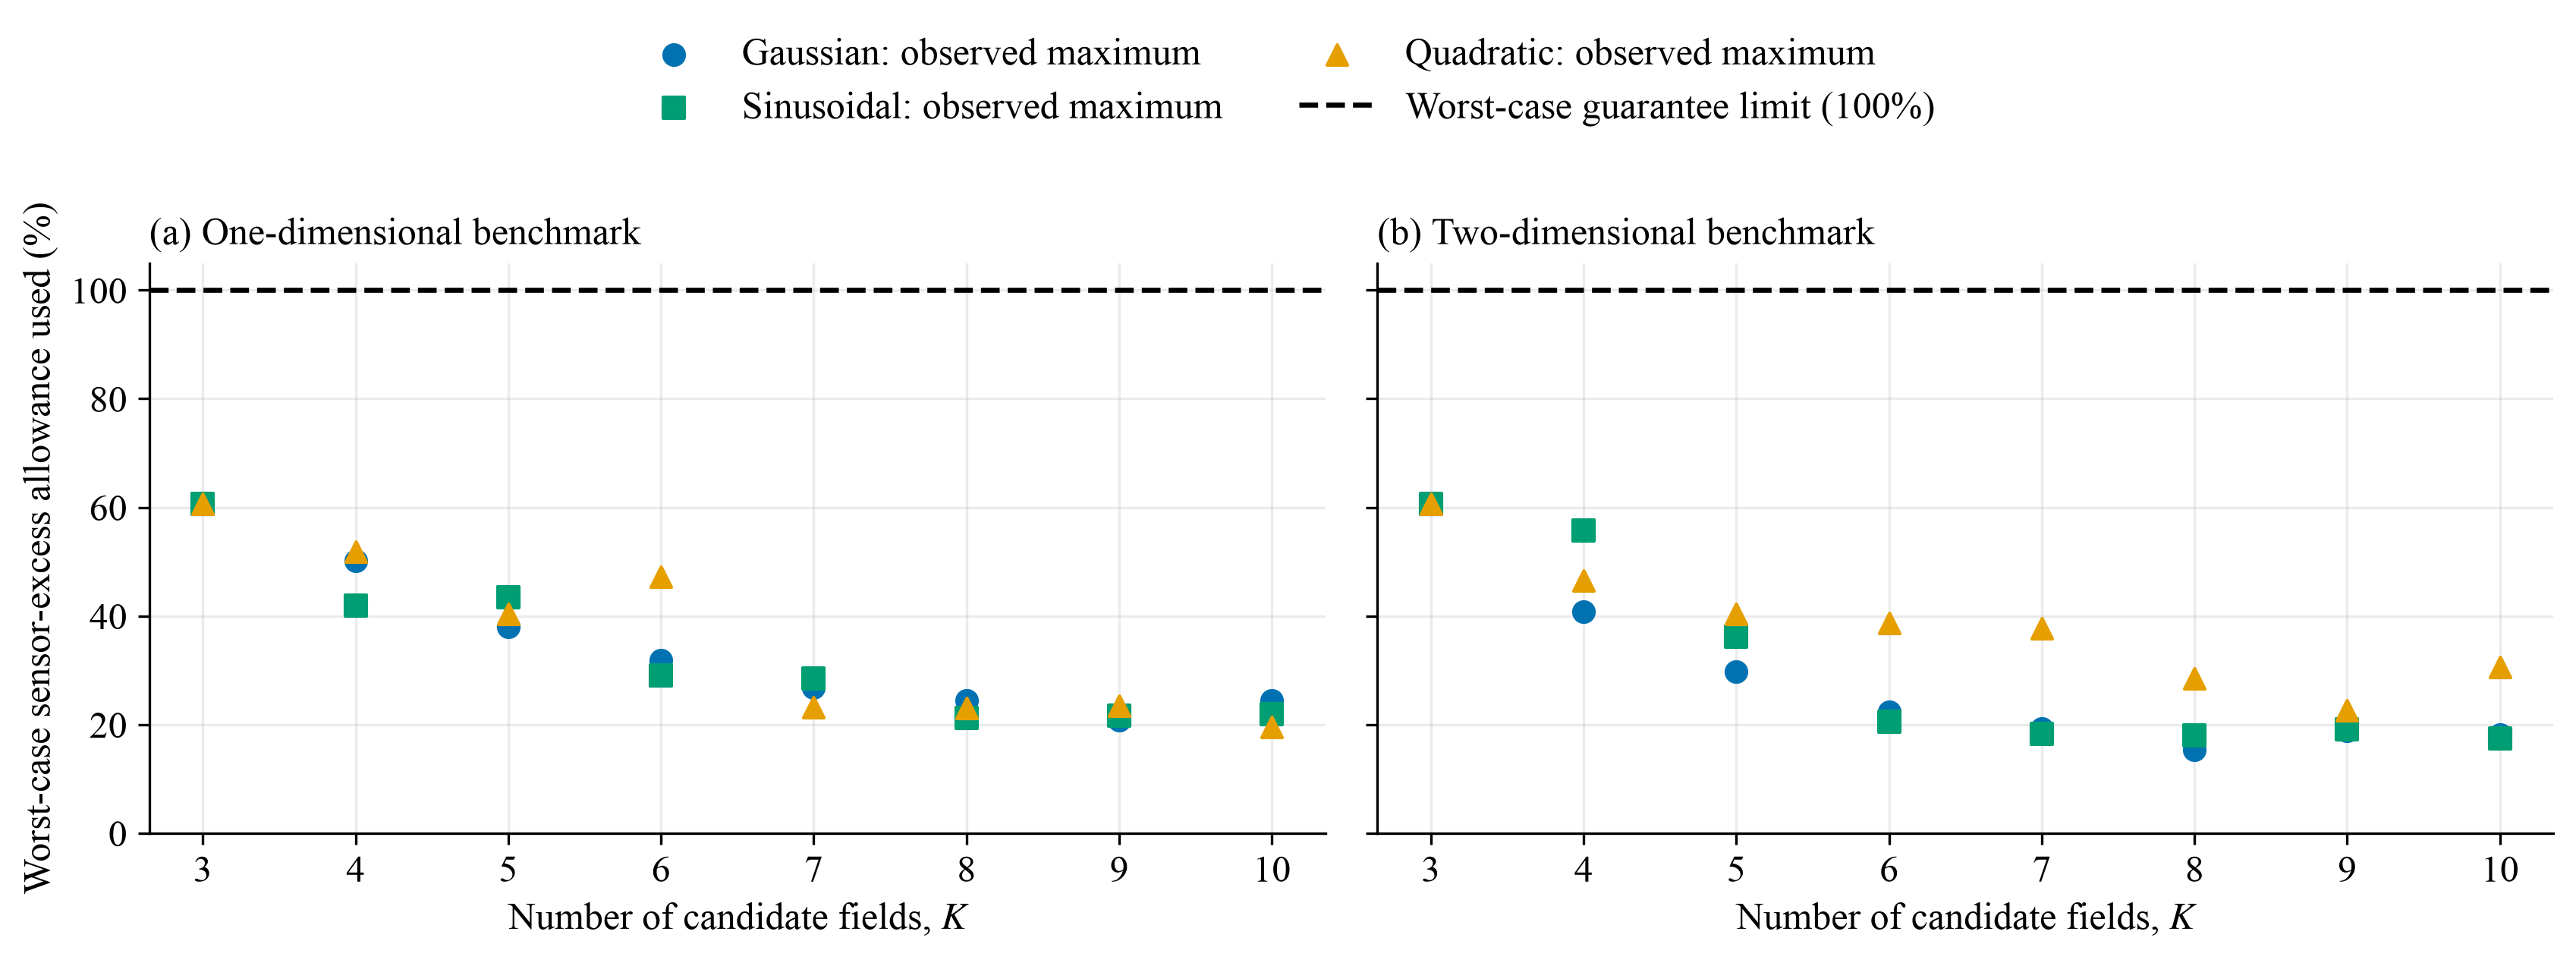

### Quality heatmaps

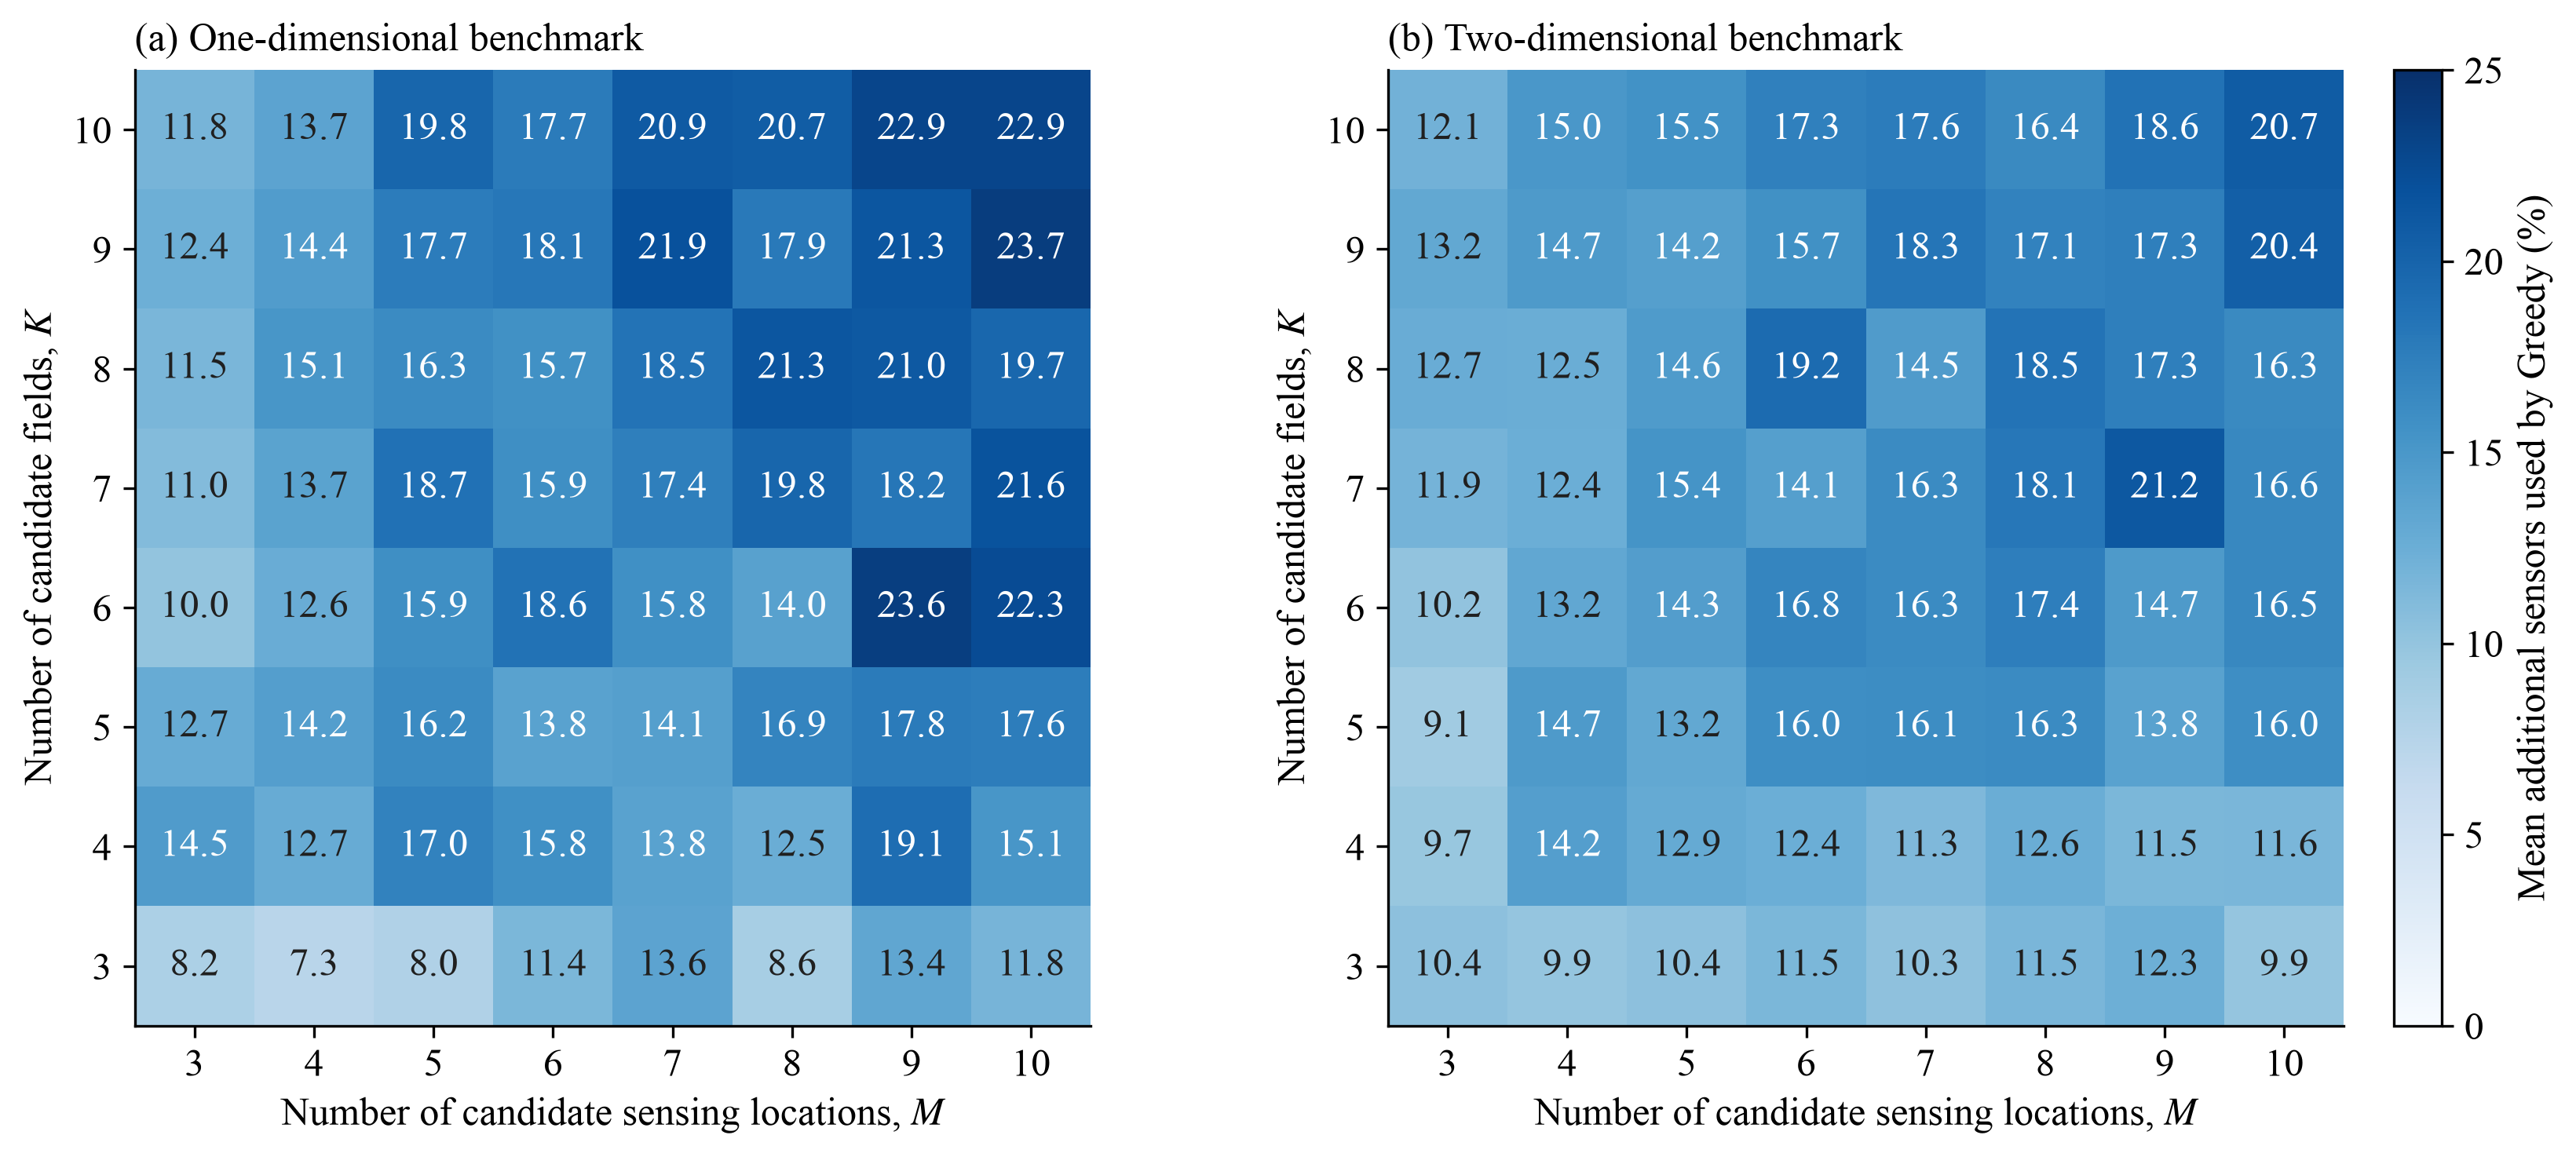

### Mean exact minimum sensor budget by $K$

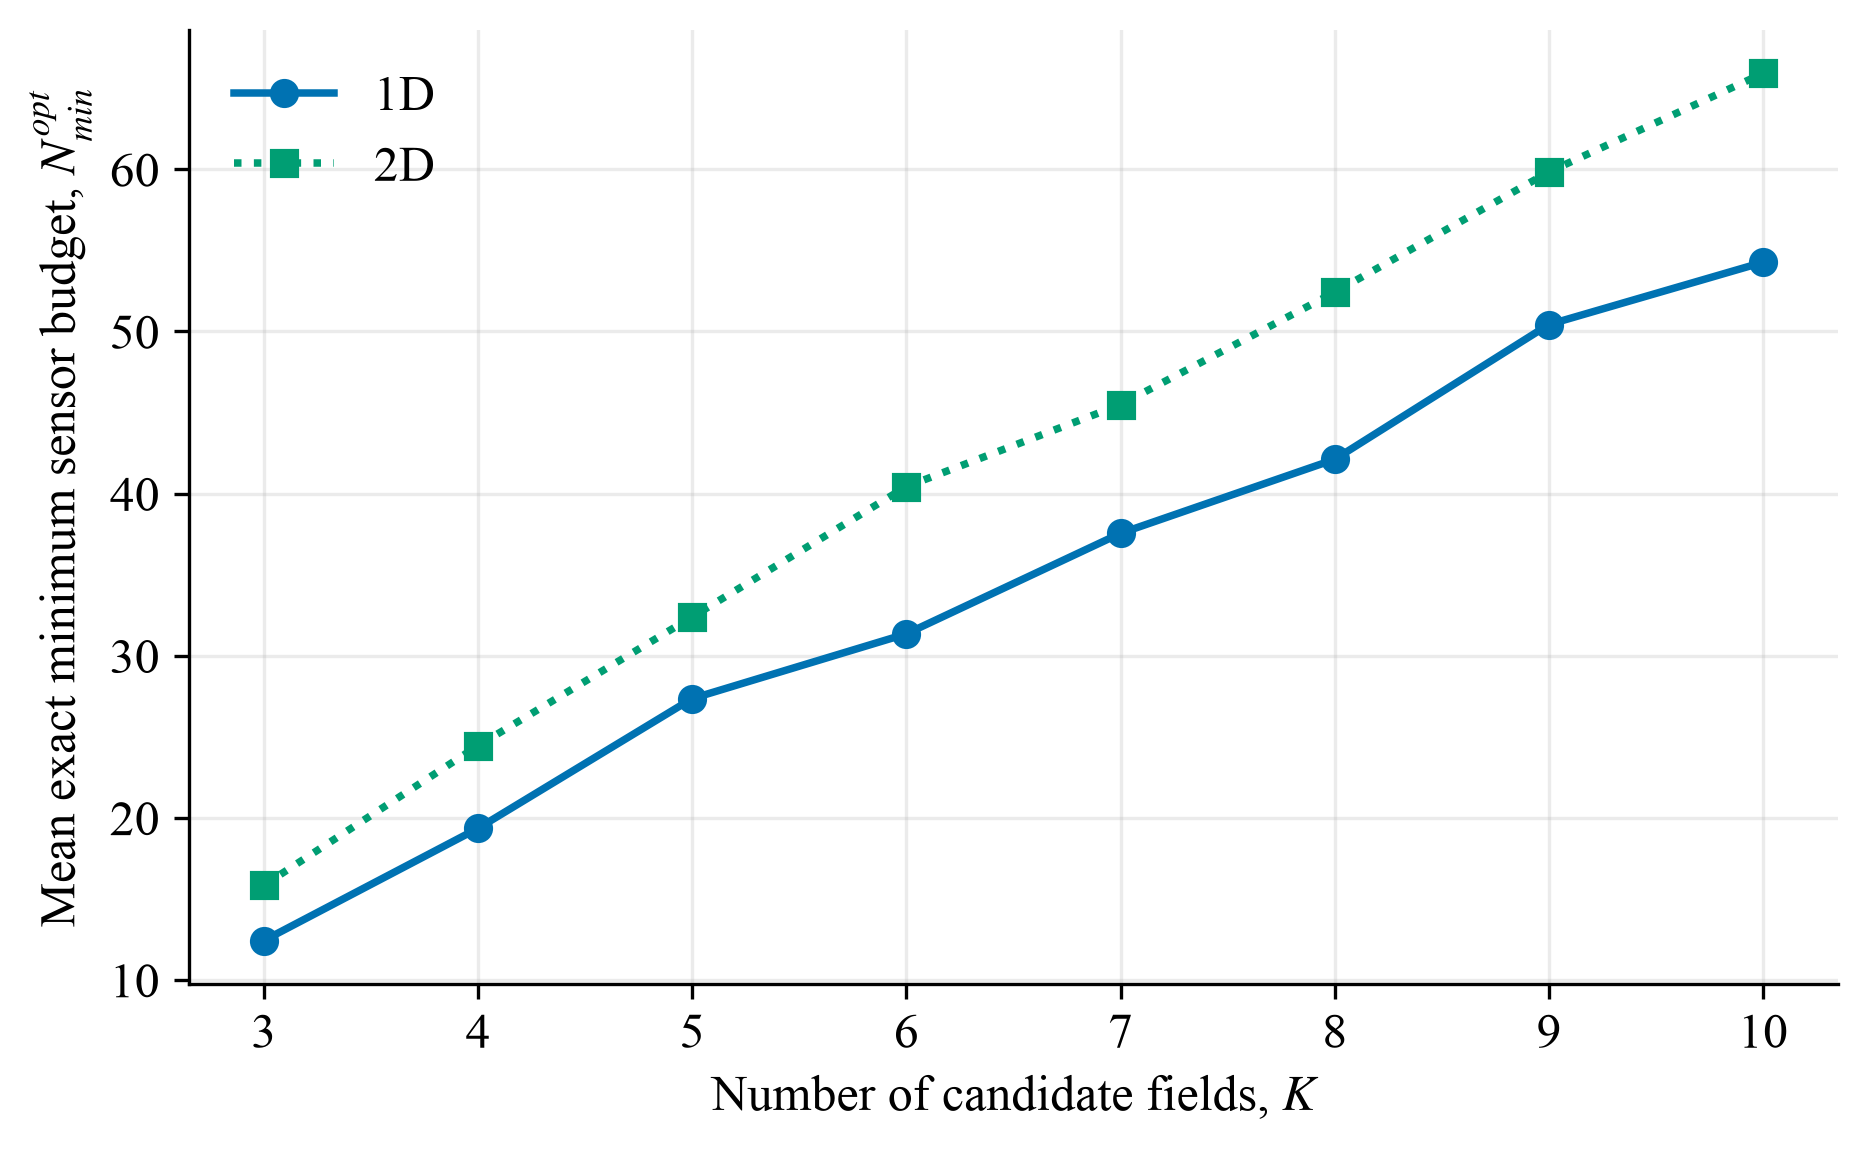

In [31]:
# Display the selected publication figures in the requested order.
PUBLICATION_FIGURES = ("families", "guarantee", "heatmaps", "nmin")
plot_titles = {
    "families": "Sensor excess by field family",
    "guarantee": "Approximation guarantee comparison",
    "heatmaps": "Quality heatmaps",
    "nmin": r"Mean exact minimum sensor budget by $K$",
}
plot_files = {
    "families": "benchmark_family_excess.png",
    "guarantee": "benchmark_guarantee_comparison.png",
    "heatmaps": "benchmark_quality_heatmaps.png",
    "nmin": "benchmark_nmin_by_k.png",
}
figure_directory = Path(analysis["output_directory"]) / "figures"
for figure_key in PUBLICATION_FIGURES:
    display(Markdown(f"### {plot_titles[figure_key]}"))
    display(Image(filename=str(figure_directory / plot_files[figure_key])))


## Saved Files

Detailed result tables are saved under `results/algorithm_comparison/<dataset>_results_full/tables/`. Combined analysis tables and the four PNG/PDF publication figure pairs are saved under `results/algorithm_comparison/results_summary_benchmark_1d_benchmark_2d_full/`.
